# Notebook 13 – EDA Report


## 1. Import Required Libraries

We use:
- `pandas` to inspect and summarize tabular data.
- `numpy` for numerical operations.
- `matplotlib` for charts.
- `Path` to check whether a file exists.

If a library is missing in your Anaconda environment, install it from Anaconda Prompt or run `!pip install library_name` in a notebook cell.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Dataset

### Option A – Use the built-in sample dataset (recommended first)
The next cell creates sample retail sales data. It includes a few missing values and a duplicate row so that you can practise EDA checks.

### Option B – Load your own CSV file
After the sample notebook runs successfully, set `USE_OWN_CSV = True` and enter the correct CSV filename or full path. The file must exist at that location.

**Common mistake:** `your_dataset.csv` is only a placeholder. If you leave it unchanged, Python will report `FileNotFoundError`.

In [3]:
USE_OWN_CSV = False
CSV_PATH = "your_dataset.csv"  # Change this to your real file path if USE_OWN_CSV = True

if USE_OWN_CSV:
    csv_file = Path(CSV_PATH)
    if not csv_file.is_file():
        raise FileNotFoundError(
            f"CSV file not found: {csv_file.resolve()}\n"
            "Check the filename and folder, or set USE_OWN_CSV = False to use sample data."
        )
    df = pd.read_csv(csv_file)
    print("Your CSV dataset loaded successfully.")
else:
    rng = np.random.default_rng(42)
    n = 60
    df = pd.DataFrame({
        "Order_ID": [f"ORD{i:03d}" for i in range(1, n + 1)],
        "Customer_Age": rng.integers(18, 66, size=n),
        "City": rng.choice(["Hyderabad", "Chennai", "Bengaluru", "Delhi"], size=n),
        "Category": rng.choice(["Electronics", "Clothing", "Grocery"], size=n),
        "Quantity": rng.integers(1, 6, size=n),
        "Unit_Price": rng.choice([100, 150, 200, 250, 300, 500], size=n),
        "Order_Date": pd.date_range("2026-01-01", periods=n, freq="D").astype(str),
        "Returned": rng.choice(["Yes", "No"], size=n, p=[0.15, 0.85])
    })
    df["Sales"] = df["Quantity"] * df["Unit_Price"]
    df.loc[4, "Customer_Age"] = np.nan
    df.loc[9, "City"] = np.nan
    df.loc[14, "Unit_Price"] = -50  # Intentionally invalid for investigation
    df = pd.concat([df, df.iloc[[0]]], ignore_index=True)  # One intentional duplicate
    print("Sample dataset created successfully.")

display(df.head())
print("Dataset shape:", df.shape)

Sample dataset created successfully.


,Order_ID,Customer_Age,City,Category,Quantity,Unit_Price,Order_Date,Returned,Sales
0,ORD001,22.0,Delhi,Clothing,5,100,2026-01-01,No,500
1,ORD002,55.0,Bengaluru,Grocery,1,250,2026-01-02,No,250
2,ORD003,49.0,Chennai,Clothing,3,100,2026-01-03,Yes,300
3,ORD004,39.0,Delhi,Clothing,4,250,2026-01-04,No,1000
4,ORD005,NaN,Chennai,Grocery,3,250,2026-01-05,Yes,750


Dataset shape: (61, 9)


## 3. Dataset Overview

A dataset overview explains what data is being analyzed.

### Topics
- **Dataset source:** Where the data came from.
- **Dataset size:** Number of rows and columns.
- **Features:** Input columns or variables.
- **Target:** The column you want to explain or predict, if one exists.
- **Domain:** The subject area, such as retail, healthcare, banking, or education.

**Simple example:** In student data, study hours and attendance can be features, while exam result may be the target.

**Real-world example:** A hospital dataset may contain age, symptoms, test results, and diagnosis.

**Business example:** A retail dataset may contain product, quantity, price, city, and sales.

**AI/ML use case:** Understanding features and target helps decide what information is available to a model.

**Why important:** Without understanding the columns and their meaning, analysis may answer the wrong question.

In [4]:
# Update these descriptions to match your real dataset.
DATASET_SOURCE = "Built-in sample data (replace with your source)"
DOMAIN = "Retail sales"
TARGET_COLUMN = "Sales"  # Change to your target column, or use None if there is no target.

print("Dataset source:", DATASET_SOURCE)
print("Domain:", DOMAIN)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:", df.columns.tolist())
print("Target column:", TARGET_COLUMN if TARGET_COLUMN in df.columns else "Not available / not specified")

overview = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(dtype) for dtype in df.dtypes],
    "Non-Null Count": [int(df[col].notna().sum()) for col in df.columns],
    "Missing Count": [int(df[col].isna().sum()) for col in df.columns],
    "Unique Values": [int(df[col].nunique(dropna=True)) for col in df.columns]
})
display(overview)

Dataset source: Built-in sample data (replace with your source)
Domain: Retail sales
Rows: 61
Columns: 9
Column names: ['Order_ID', 'Customer_Age', 'City', 'Category', 'Quantity', 'Unit_Price', 'Order_Date', 'Returned', 'Sales']
Target column: Sales


,Column,Data Type,Non-Null Count,Missing Count,Unique Values
0,Order_ID,str,61,0,60
1,Customer_Age,float64,60,1,31
2,City,str,60,1,4
3,Category,str,61,0,3
4,Quantity,int64,61,0,5
5,Unit_Price,int64,61,0,7
6,Order_Date,str,61,0,60
7,Returned,str,61,0,2
8,Sales,int64,61,0,17


## 4. Data Inspection

Data inspection is the first look at the structure and contents of a dataset.

Useful commands:
- `head()` – first rows.
- `tail()` – last rows.
- `shape` – rows and columns.
- `columns` – column names.
- `info()` – data types and non-null counts.
- `describe()` – numerical summary.

- **Simple example:** Check the first five student records.
- **Real-world example:** Inspect incoming sensor readings before analysis.
- **Business example:** Review imported orders before preparing a sales report.
- **AI/ML use case:** Inspect feature columns and target values before splitting data.
- **Why required:** It helps detect unexpected columns, types, missing values, and unusual values early.

In [4]:
print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Shape (rows, columns):", df.shape)
print("Column names:", df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe(include=[np.number]).T)

First 5 rows:


,Order_ID,Customer_Age,City,Category,Quantity,Unit_Price,Order_Date,Returned,Sales
0,ORD001,22.0,Delhi,Clothing,5,100,2026-01-01,No,500
1,ORD002,55.0,Bengaluru,Grocery,1,250,2026-01-02,No,250
2,ORD003,49.0,Chennai,Clothing,3,100,2026-01-03,Yes,300
3,ORD004,39.0,Delhi,Clothing,4,250,2026-01-04,No,1000
4,ORD005,NaN,Chennai,Grocery,3,250,2026-01-05,Yes,750


Last 5 rows:


,Order_ID,Customer_Age,City,Category,Quantity,Unit_Price,Order_Date,Returned,Sales
56,ORD057,44.0,Hyderabad,Grocery,4,500,2026-02-26,Yes,2000
57,ORD058,25.0,Hyderabad,Electronics,3,200,2026-02-27,No,600
58,ORD059,53.0,Hyderabad,Grocery,2,150,2026-02-28,Yes,300
59,ORD060,50.0,Hyderabad,Clothing,4,100,2026-03-01,No,400
60,ORD001,22.0,Delhi,Clothing,5,100,2026-01-01,No,500


Shape (rows, columns): (61, 9)
Column names: ['Order_ID', 'Customer_Age', 'City', 'Category', 'Quantity', 'Unit_Price', 'Order_Date', 'Returned', 'Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      61 non-null     object 
 1   Customer_Age  60 non-null     float64
 2   City          60 non-null     object 
 3   Category      61 non-null     object 
 4   Quantity      61 non-null     int64  
 5   Unit_Price    61 non-null     int64  
 6   Order_Date    61 non-null     object 
 7   Returned      61 non-null     object 
 8   Sales         61 non-null     int64  
dtypes: float64(1), int64(3), object(5)
memory usage: 4.4+ KB

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Customer_Age,60.0,42.483333,13.449834,20.0,30.25,43.5,54.0,64.0
Quantity,61.0,3.032787,1.303421,1.0,2.00,3.0,4.0,5.0
Unit_Price,61.0,215.573770,118.511949,-50.0,150.00,200.0,250.0,500.0
Sales,61.0,645.081967,413.390949,100.0,300.00,600.0,800.0,2000.0


## 5. Data Quality Analysis

Data quality checks whether data is suitable for the analysis purpose.

### 5.1 Missing Values
Missing values are blank or unavailable entries.

- **Simple:** A student's mark is blank.
- **Real-world:** A sensor did not record a reading.
- **Business:** An order has no delivery city.
- **AI/ML:** Missing feature values may require imputation or a model that supports missing values.
- **Why important:** Missingness can reduce the usable data or bias conclusions.

### 5.2 Duplicates
Duplicates are repeated records. A repeated row is not always an error; verify the business key and context before removing it.

### 5.3 Invalid Values
Values that break known rules, such as a negative quantity or impossible age, should be investigated.

### 5.4 Data-Type Issues
A date stored as text or a price stored as text may prevent correct calculations.

### 5.5 Consistency
The same category should use a consistent representation, such as `Hyderabad` rather than multiple spellings.

In [5]:
print("Missing values by column:")
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2)
})
display(missing_summary)

print("Exact duplicate rows:", int(df.duplicated().sum()))

print("Data types:")
display(df.dtypes.astype(str).to_frame("Data_Type"))

# Example rule checks; change rules to match your own dataset.
if "Customer_Age" in df.columns:
    invalid_age = df["Customer_Age"].notna() & ~df["Customer_Age"].between(0, 120)
    print("Invalid Customer_Age rows:", int(invalid_age.sum()))

if "Quantity" in df.columns:
    invalid_quantity = df["Quantity"].notna() & (df["Quantity"] < 0)
    print("Negative Quantity rows:", int(invalid_quantity.sum()))

if "Unit_Price" in df.columns:
    invalid_price = df["Unit_Price"].notna() & (df["Unit_Price"] < 0)
    print("Negative Unit_Price rows:", int(invalid_price.sum()))

Missing values by column:


,Missing_Count,Missing_Percent
Order_ID,0,0.00
Customer_Age,1,1.64
City,1,1.64
Category,0,0.00
Quantity,0,0.00
Unit_Price,0,0.00
Order_Date,0,0.00
Returned,0,0.00
Sales,0,0.00


Exact duplicate rows: 1
Data types:


,Data_Type
Order_ID,object
Customer_Age,float64
City,object
Category,object
Quantity,int64
Unit_Price,int64
Order_Date,object
Returned,object
Sales,int64


Invalid Customer_Age rows: 0
Negative Quantity rows: 0
Negative Unit_Price rows: 1


## 6. Statistical Findings

Statistics describe the center, spread, and shape of numerical data.

### Central tendency
- **Mean:** Arithmetic average.
- **Median:** Middle value after sorting.
- **Mode:** Most frequent value.

### Dispersion
- **Range:** Maximum minus minimum.
- **Variance:** Average squared distance from the mean (sample variance in pandas by default).
- **Standard deviation:** Typical spread around the mean.
- **IQR:** Third quartile minus first quartile.

### Distribution
Skewness describes asymmetry. Kurtosis describes tail weight/peakedness relative to a normal distribution (pandas uses excess kurtosis).

### Outliers
An outlier is an unusually distant observation. It may be an error, a rare but valid case, or an important event. Do not delete it automatically.

- **Simple:** One unusually high exam score.
- **Real-world:** An exceptional but genuine temperature reading.
- **Business:** A bulk purchase creates a very large order value.
- **AI/ML:** Extreme values can influence models such as linear regression.
- **Why important:** Statistical summaries help understand patterns and decide what needs investigation.

In [6]:
numeric_df = df.select_dtypes(include="number")

if numeric_df.empty:
    print("No numerical columns found. Check the data types or select numeric columns.")
else:
    stats = numeric_df.describe().T
    stats["median"] = numeric_df.median()
    stats["mode"] = numeric_df.mode().iloc[0] if not numeric_df.mode().empty else np.nan
    stats["variance"] = numeric_df.var()
    stats["skewness"] = numeric_df.skew()
    stats["kurtosis"] = numeric_df.kurtosis()
    stats["range"] = numeric_df.max() - numeric_df.min()
    stats["IQR"] = numeric_df.quantile(0.75) - numeric_df.quantile(0.25)
    display(stats.round(2))

,count,mean,std,min,25%,50%,75%,max,median,mode,variance,skewness,kurtosis,range,IQR
Customer_Age,60.0,42.48,13.45,20.0,30.25,43.5,54.0,64.0,43.5,22.0,180.90,-0.24,-1.22,44.0,23.75
Quantity,61.0,3.03,1.30,1.0,2.00,3.0,4.0,5.0,3.0,4.0,1.70,-0.06,-1.12,4.0,2.00
Unit_Price,61.0,215.57,118.51,-50.0,150.00,200.0,250.0,500.0,200.0,100.0,14045.08,1.04,1.25,550.0,100.00
Sales,61.0,645.08,413.39,100.0,300.00,600.0,800.0,2000.0,600.0,300.0,170892.08,1.42,2.39,1900.0,500.00


## 7. Outlier Summary Using the IQR Rule

For a numerical column:
- Q1 = 25th percentile
- Q3 = 75th percentile
- IQR = Q3 − Q1
- Lower boundary = Q1 − 1.5 × IQR
- Upper boundary = Q3 + 1.5 × IQR

Values outside these boundaries are flagged for investigation, not automatically deleted.

**Business example:** A very large order may be a genuine wholesale order.

**AI/ML use case:** Compare model performance with and without an outlier treatment only when there is a justified reason, using training data appropriately.

In [7]:
def iqr_outlier_report(data, columns=None):
    if columns is None:
        columns = data.select_dtypes(include="number").columns.tolist()
    rows = []
    for col in columns:
        series = pd.to_numeric(data[col], errors="coerce").dropna()
        if series.empty:
            continue
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = int(((series < lower) | (series > upper)).sum())
        rows.append({
            "Column": col, "Q1": q1, "Q3": q3, "IQR": iqr,
            "Lower_Bound": lower, "Upper_Bound": upper,
            "Outlier_Count": count
        })
    return pd.DataFrame(rows)

outlier_report = iqr_outlier_report(df)
display(outlier_report.round(2))
print("Interpretation: investigate flagged values; do not remove them without understanding their cause.")

,Column,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
0,Customer_Age,30.25,54.0,23.75,-5.38,89.62,0
1,Quantity,2.00,4.0,2.00,-1.00,7.00,0
2,Unit_Price,150.00,250.0,100.00,0.00,400.00,7
3,Sales,300.00,800.0,500.00,-450.00,1550.00,2


Interpretation: investigate flagged values; do not remove them without understanding their cause.


## 8. Relationships Between Features

Relationship analysis explores how variables change together.

- **Correlation:** Measures the strength and direction of a linear relationship between numerical variables.
- **Positive correlation:** Both variables tend to increase together.
- **Negative correlation:** One tends to increase as the other decreases.
- **Weak correlation:** Little linear relationship is observed.
- **Important caution:** Correlation does not prove causation.

**Simple example:** Study hours and marks may have a positive relationship.

**Real-world example:** Outdoor temperature and electricity demand may be related.

**Business example:** Advertising spend and sales may move together.

**AI/ML use case:** Highly correlated features may create multicollinearity in some models.

**Why important:** Relationships help identify useful features, patterns, and questions for further investigation.

In [8]:
corr_df = df.select_dtypes(include="number").corr()

if corr_df.empty or corr_df.shape[1] < 2:
    print("At least two numerical columns are needed for a correlation matrix.")
else:
    display(corr_df.round(2))

,Customer_Age,Quantity,Unit_Price,Sales
Customer_Age,1.00,-0.10,0.23,0.20
Quantity,-0.10,1.00,-0.22,0.51
Unit_Price,0.23,-0.22,1.00,0.61
Sales,0.20,0.51,0.61,1.00


## 9. EDA Visualizations

A chart should answer a question. Choose the chart based on the data and the question.

| Chart | Useful for |
|---|---|
| Histogram | Distribution of one numerical feature |
| Box plot | Spread and potential outliers |
| Bar chart | Counts or summary by category |
| Scatter plot | Relationship between two numerical features |
| Correlation heatmap | Correlations among numerical features |

**Why important:** Visualizations can reveal skewness, unusual values, group differences, and relationships that are difficult to notice in tables.

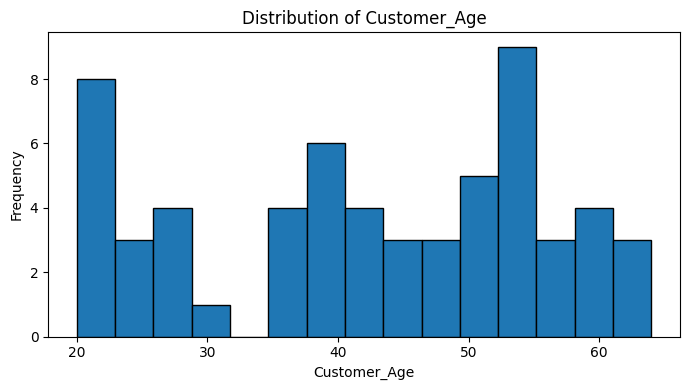

In [9]:
# Histogram: distribution of a numerical column
numeric_columns = df.select_dtypes(include="number").columns.tolist()

if numeric_columns:
    col = numeric_columns[0]
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if not values.empty:
        plt.figure(figsize=(7, 4))
        plt.hist(values, bins=15, edgecolor="black")
        plt.title(f"Distribution of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()
    else:
        print(f"{col} has no valid numeric values.")
else:
    print("No numerical columns available for a histogram.")

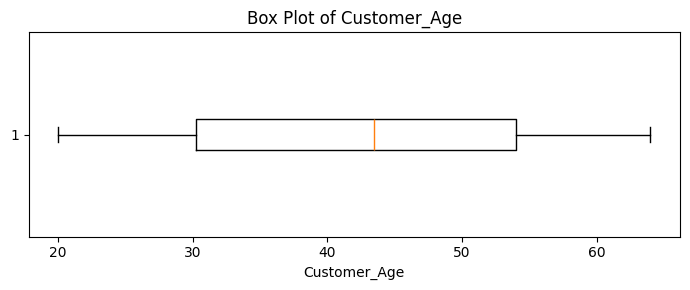

In [10]:
# Box plot: compare spread and flag potential outliers
if numeric_columns:
    col = numeric_columns[0]
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if not values.empty:
        plt.figure(figsize=(7, 3))
        plt.boxplot(values, vert=False)
        plt.title(f"Box Plot of {col}")
        plt.xlabel(col)
        plt.tight_layout()
        plt.show()

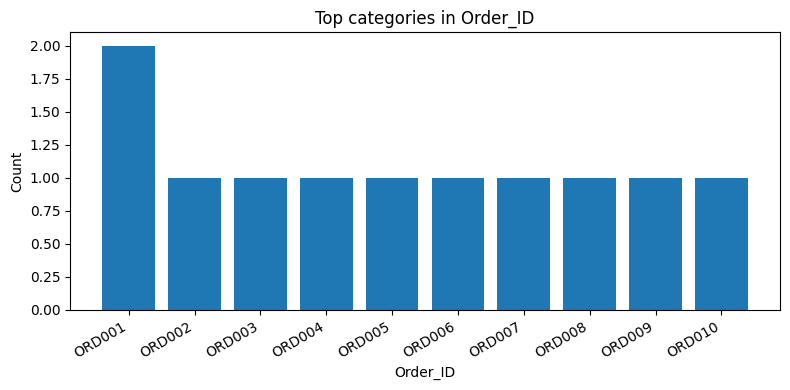

In [11]:
# Bar chart: count values in the first categorical column
categorical_columns = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

if categorical_columns:
    col = categorical_columns[0]
    counts = df[col].fillna("Missing").astype(str).value_counts().head(10)
    plt.figure(figsize=(8, 4))
    plt.bar(counts.index, counts.values)
    plt.title(f"Top categories in {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No categorical columns available for a bar chart.")

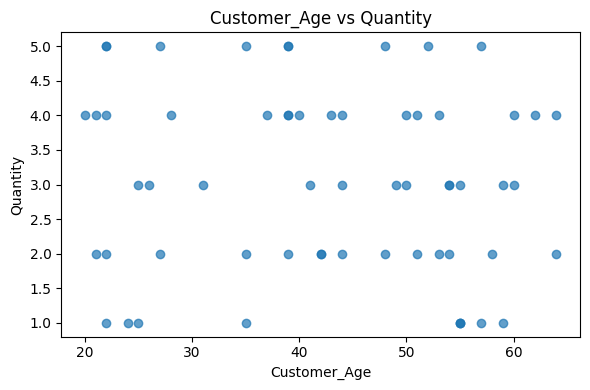

In [12]:
# Scatter plot: first two numerical columns
if len(numeric_columns) >= 2:
    x_col, y_col = numeric_columns[0], numeric_columns[1]
    plot_df = df[[x_col, y_col]].apply(pd.to_numeric, errors="coerce").dropna()
    if not plot_df.empty:
        plt.figure(figsize=(6, 4))
        plt.scatter(plot_df[x_col], plot_df[y_col], alpha=0.7)
        plt.title(f"{x_col} vs {y_col}")
        plt.xlabel(x_col)
        plt.ylabel(y_col)
        plt.tight_layout()
        plt.show()
else:
    print("At least two numerical columns are needed for a scatter plot.")

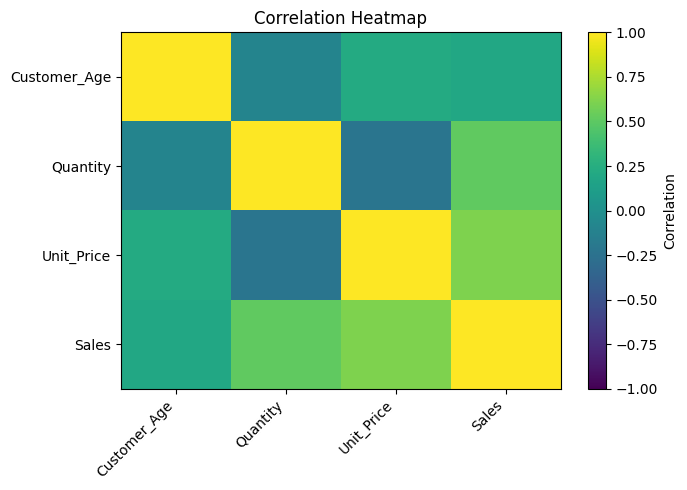

In [13]:
# Correlation heatmap using matplotlib only (no seaborn dependency)
corr = df.select_dtypes(include="number").corr()

if corr.shape[1] >= 2:
    fig, ax = plt.subplots(figsize=(7, 5))
    image = ax.imshow(corr, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(corr.columns)))
    ax.set_yticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.columns)
    ax.set_title("Correlation Heatmap")
    fig.colorbar(image, ax=ax, label="Correlation")
    plt.tight_layout()
    plt.show()
else:
    print("At least two numerical columns are needed for a correlation heatmap.")

## 10. Target Variable Analysis

A target is the value we want to explain or predict. If the dataset has no target, state that clearly.

- **Classification target:** Categories such as `Yes/No`, `Pass/Fail`, or `Fraud/Not Fraud`.
- **Regression target:** A numerical value such as price, sales, or house value.

For a classification target, inspect class counts and percentages. For a regression target, inspect summary statistics and distribution.

**Why important:** Target analysis reveals imbalance, unusual values, and whether the intended prediction problem is classification or regression.

Target column: Sales
Missing target values: 0
Unique target values: 17
This appears to be a numerical target (often a regression task).


,Target_Statistics
count,61.000000
mean,645.081967
std,413.390949
min,100.000000
25%,300.000000
50%,600.000000
75%,800.000000
max,2000.000000


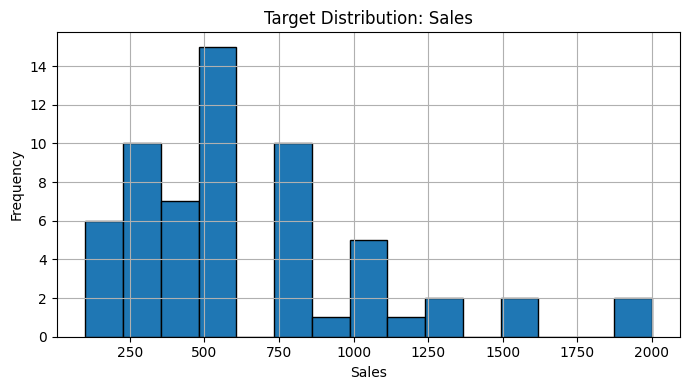

In [14]:
if TARGET_COLUMN is None or TARGET_COLUMN not in df.columns:
    print("Target column is not configured or is not present in this dataset.")
else:
    target = df[TARGET_COLUMN]
    print("Target column:", TARGET_COLUMN)
    print("Missing target values:", int(target.isna().sum()))
    print("Unique target values:", int(target.nunique(dropna=True)))

    if pd.api.types.is_numeric_dtype(target) and target.nunique(dropna=True) > 10:
        print("This appears to be a numerical target (often a regression task).")
        display(target.describe().to_frame("Target_Statistics"))
        target.dropna().hist(bins=15, edgecolor="black", figsize=(7, 4))
        plt.title(f"Target Distribution: {TARGET_COLUMN}")
        plt.xlabel(TARGET_COLUMN)
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()
    else:
        print("This appears to be a categorical target (often a classification task).")
        counts = target.fillna("Missing").astype(str).value_counts()
        percentages = (counts / counts.sum() * 100).round(2)
        target_summary = pd.DataFrame({"Count": counts, "Percentage": percentages})
        display(target_summary)

## 11. Business Insights

Business insights explain what the analysis may mean for a real decision.

A useful insight contains:
1. **Finding:** What did the data show?
2. **Evidence:** Which count, percentage, statistic, or chart supports it?
3. **Possible meaning:** What might explain the pattern?
4. **Action:** What should the business investigate or do next?

- **Simple example:** One category has the highest number of records.
- **Real-world example:** A hospital may investigate why waiting times are higher on certain days.
- **Business example:** A retailer may review stock levels for products with high sales.
- **AI/ML use case:** Findings can guide feature selection and model evaluation.
- **Why important:** EDA should lead to understandable findings, not just a collection of charts.

Do not claim that one factor caused another based only on correlation.

In [15]:
# Generate a few cautious, data-based observations where columns are available.
print("POTENTIAL BUSINESS OBSERVATIONS")

if "Category" in df.columns:
    print("\nRecord count by category:")
    display(df["Category"].value_counts(dropna=False).to_frame("Record_Count"))

if "City" in df.columns:
    print("\nRecord count by city:")
    display(df["City"].value_counts(dropna=False).to_frame("Record_Count"))

if "Sales" in df.columns:
    sales_by_category = df.groupby("Category", dropna=False)["Sales"].sum().sort_values(ascending=False) if "Category" in df.columns else None
    if sales_by_category is not None:
        print("\nTotal sales by category (descriptive, not causal):")
        display(sales_by_category.to_frame("Total_Sales"))

POTENTIAL BUSINESS OBSERVATIONS

Record count by category:


,Record_Count
Category,
Clothing,25
Grocery,18
Electronics,18



Record count by city:


,Record_Count
City,
Delhi,18
Chennai,15
Hyderabad,14
Bengaluru,13
NaN,1



Total sales by category (descriptive, not causal):


,Total_Sales
Category,
Clothing,16200
Grocery,12250
Electronics,10900


## 12. Problems Identified and Recommendations

A report should separate **observed problems** from **recommended next steps**.

Examples:
- Missing values → investigate why values are missing; choose a suitable treatment.
- Duplicate records → verify the unique key and remove only confirmed duplicates in a separate cleaning step.
- Invalid negative prices → check the source system or business rules.
- Incorrect data types → convert using explicit, validated rules.
- Extreme values → verify whether they are errors or valid exceptional events.
- Class imbalance → consider suitable metrics and modelling strategies if building a classifier.
- Potential leakage → remove features unavailable at prediction time.

**Important:** This notebook reports issues. It does not perform a complete preprocessing operation or overwrite your original dataset.

In [16]:
recommendations = []

missing_total = int(df.isna().sum().sum())
duplicate_total = int(df.duplicated().sum())

if missing_total > 0:
    recommendations.append(
        f"Investigate {missing_total} missing cell(s); understand the reason before choosing an imputation or exclusion strategy."
    )
else:
    recommendations.append("No missing cells detected in the current dataset.")

if duplicate_total > 0:
    recommendations.append(
        f"Review {duplicate_total} exact duplicate row(s); confirm whether they are genuine duplicates before removing."
    )
else:
    recommendations.append("No exact duplicate rows detected.")

if "Unit_Price" in df.columns and (pd.to_numeric(df["Unit_Price"], errors="coerce") < 0).any():
    recommendations.append("Investigate negative Unit_Price values against the business rules and source records.")

if "Customer_Age" in df.columns:
    age_values = pd.to_numeric(df["Customer_Age"], errors="coerce")
    if ((age_values < 0) | (age_values > 120)).any():
        recommendations.append("Review Customer_Age values outside the expected range.")

recommendations.append("Check whether each feature would be available at the time a future prediction is made to prevent data leakage.")
recommendations.append("Keep a copy of the raw dataset and document every cleaning decision in a separate preprocessing workflow.")

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

1. Investigate 2 missing cell(s); understand the reason before choosing an imputation or exclusion strategy.
2. Review 1 exact duplicate row(s); confirm whether they are genuine duplicates before removing.
3. Investigate negative Unit_Price values against the business rules and source records.
4. Check whether each feature would be available at the time a future prediction is made to prevent data leakage.
5. Keep a copy of the raw dataset and document every cleaning decision in a separate preprocessing workflow.


## 14. Important EDA Rules

1. Understand the meaning of each column before analyzing it.
2. Do not assume every unusual value is an error.
3. Do not remove every outlier automatically.
4. Do not fill missing values without understanding the context.
5. Do not treat correlation as proof of causation.
6. Do not use information from the future when building a predictive model.
7. Keep the original dataset unchanged during EDA.
8. Record findings and recommendations clearly.

### Final Learning Outcome
After completing this notebook, you should be able to inspect a dataset, summarize its quality, calculate statistics, explore relationships, create suitable charts, identify potential problems, and write an EDA report.